---
title: "Identical Particles — Level 2"
short_title: "07 Identical Particles"
numbering:
  heading_2: true
  equation: true
---

# Identical Particles

:::{seealso} Math for this topic
- [M6: Linear algebra](../../level2-book/math/06-linear-algebra.ipynb)
- [Q-M3: Hilbert space and Dirac notation](../math/03-hilbert-space-dirac.ipynb)
- [Q-M4: Rotations, angular momentum algebra and spherical harmonics](../math/04-rotations-spherical-harmonics.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | Tipler & Mosca, ch. 36–37 | Pauli exclusion, filling electron shells |
| **2** | **Griffiths QM, ch. 5** | **Symmetrization, the exchange force, helium, the periodic table** |
| 3 | Sakurai, ch. 7 | Second quantization, Fock space |

The new skill at this level: requiring multi-particle wave functions to be symmetric or antisymmetric under exchange, and seeing how that alone shapes atoms

Math for this topic: mechanics M6 (matrices and determinants), Q-M3 (Dirac notation) and Q-M4 (adding spins).
:::

Workbook example ladder: electron configurations → the two-electron states of helium → creation and annihilation operators for fermions. Exercises have separate hint and answer dropdowns.

::::{admonition} Pre-test: can you skip this notebook?
:class: dropdown

Work these without looking at the notes. Each problem names the section it tests. If **every part** is right, skip ahead to [Time-Independent Perturbation Theory](08-time-independent-perturbation.ipynb). If you miss a part, study just the section it names and try that problem again.

1. **Two Particles, One Wave Function**

   (a) Two identical particles occupy the one-particle states $\psi_a$ and $\psi_b$. Write the normalized two-particle wave function for bosons and for fermions.

   (b) Show that the fermion wave function vanishes if $a = b$. What principle is this?

2. **The Exchange "Force"**

   Do identical bosons tend to be found closer together or farther apart than distinguishable particles in the same states? What about fermions? Why isn't this a real force?

3. **Spin Enters: Space Times Spin**

   Two electrons are in a spin singlet. Is their spatial wave function symmetric or antisymmetric? Which spin state (singlet or triplet) usually has lower Coulomb repulsion energy, and why?

4. **Helium**

   (a) Ignoring electron–electron repulsion, find the ground-state energy of helium.

   (b) The measured ground state is $-79.0$ eV. Find the energy needed to remove one electron.

5. **The Periodic Table**

   (a) Write the ground-state configuration of oxygen ($Z = 8$), and its total spin from Hund's first rule.

   (b) How many electrons fit in the $n = 3$ shell?

   (c) Why is sodium easy to ionize?

6. **Slater Determinants**

   Why does writing a many-electron state as a determinant guarantee antisymmetry and the exclusion principle?

:::{dropdown} Answers
1. (a) $\psi_\pm = \dfrac{1}{\sqrt2}\left[\psi_a(x_1)\psi_b(x_2) \pm \psi_b(x_1)\psi_a(x_2)\right]$: $+$ for bosons and $-$ for fermions (for $a \ne b$, orthonormal states).

   (b) With $a = b$ the two terms cancel. This is the Pauli exclusion principle.

2. Bosons are found closer together and fermions farther apart. No potential is involved: the effect comes purely from the symmetry of the wave function.

3. Symmetric. The triplet usually has lower repulsion: its antisymmetric spatial part keeps the electrons apart (Hund's rule).

4. (a) $2\times(-54.4\ \text{eV}) = -108.8$ eV.

   (b) After removing one electron, He⁺ is left at $-54.4$ eV, so the energy needed is $-54.4 - (-79.0) = 24.6$ eV.

5. (a) $1s^22s^22p^4$, with $S = 1$ (two unpaired $2p$ electrons).

   (b) $2n^2 = 18$.

   (c) Its single $3s$ electron sits outside a closed neon core, which screens most of the nuclear charge.

6. Swapping two particles swaps two rows of the determinant, which flips its sign. Two identical orbitals make two columns equal, so the determinant is zero.
:::
::::

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq
from scipy import special

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
hbar = 1.054572e-34    # J s
m_e = 9.10938e-31      # kg
eV = 1.602177e-19      # J
a0 = 5.29177e-11       # m (Bohr radius)
np.seterr(over="ignore", divide="ignore", invalid="ignore")   # plots hit inf at the edges; harmless here

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## Two Particles, One Wave Function

Two particles are described by one wave function of both positions, $\psi(\vec r_1, \vec r_2)$, with $|\psi|^2d^3r_1d^3r_2$ the probability of finding particle 1 in $d^3r_1$ *and* particle 2 in $d^3r_2$. If they do not interact, products of one-particle states are solutions: $\psi = \psi_a(\vec r_1)\psi_b(\vec r_2)$ means "particle 1 in state $a$, particle 2 in state $b$."

That labeling assumes we could tell the particles apart. Two electrons cannot be: there is no property that distinguishes them, not even in principle. So the physics must be unchanged by swapping the labels, $|\psi(\vec r_1, \vec r_2)|^2 = |\psi(\vec r_2, \vec r_1)|^2$, and since swapping twice returns the original, the swap can only multiply $\psi$ by $\pm1$:

$$
\psi_\pm(\vec r_1, \vec r_2) = \frac{1}{\sqrt2}\left[\psi_a(\vec r_1)\psi_b(\vec r_2)\pm\psi_b(\vec r_1)\psi_a(\vec r_2)\right] .
$$ (eq-symmetrized)

Nature uses both signs, decided by spin (the **spin–statistics theorem**, proved in relativistic quantum field theory):

- **bosons** (integer spin: photons, ⁴He atoms, pions) are symmetric ($+$);
- **fermions** (half-integer spin: electrons, protons, neutrons, ³He) are antisymmetric ($-$).

**The Pauli exclusion principle** is the fermion sign applied to $a = b$: $\psi_- = 0$. Two identical fermions cannot occupy the same state.

## The Exchange "Force"

Symmetrization changes where particles are found, with no force involved. Take two particles in the 1D infinite well in states $\psi_1$ and $\psi_2$ and compute the mean squared separation $\langle(x_1 - x_2)^2\rangle$:

$$
\langle(x_1 - x_2)^2\rangle_\pm = \langle(x_1 - x_2)^2\rangle_{\text{dist}}\mp2|\langle x\rangle_{12}|^2,\qquad\langle x\rangle_{12} = \int x\,\psi_1\psi_2\,dx .
$$ (eq-exchange-separation)

Bosons huddle together, fermions keep apart, compared with distinguishable particles in the same states. The effect needs the two one-particle wave functions to overlap; widely separated electrons can be treated as distinguishable.

In [2]:
x1, x2 = sp.symbols("x_1 x_2", real=True); a = sp.symbols("a", positive=True)
p1 = lambda x: sp.sqrt(2 / a) * sp.sin(sp.pi * x / a)
p2 = lambda x: sp.sqrt(2 / a) * sp.sin(2 * sp.pi * x / a)
states = {"distinguishable": p1(x1) * p2(x2),
          "bosons (+)": (p1(x1) * p2(x2) + p2(x1) * p1(x2)) / sp.sqrt(2),
          "fermions (-)": (p1(x1) * p2(x2) - p2(x1) * p1(x2)) / sp.sqrt(2)}
for name, psi in states.items():
    d2 = sp.integrate(sp.integrate((x1 - x2)**2 * psi**2, (x1, 0, a)), (x2, 0, a))
    display(Math(r"\text{" + name + r"}:\quad \sqrt{\langle(x_1-x_2)^2\rangle} = " + sp.latex(sp.N(sp.sqrt(sp.simplify(d2)) / a, 4)) + r"\,a"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

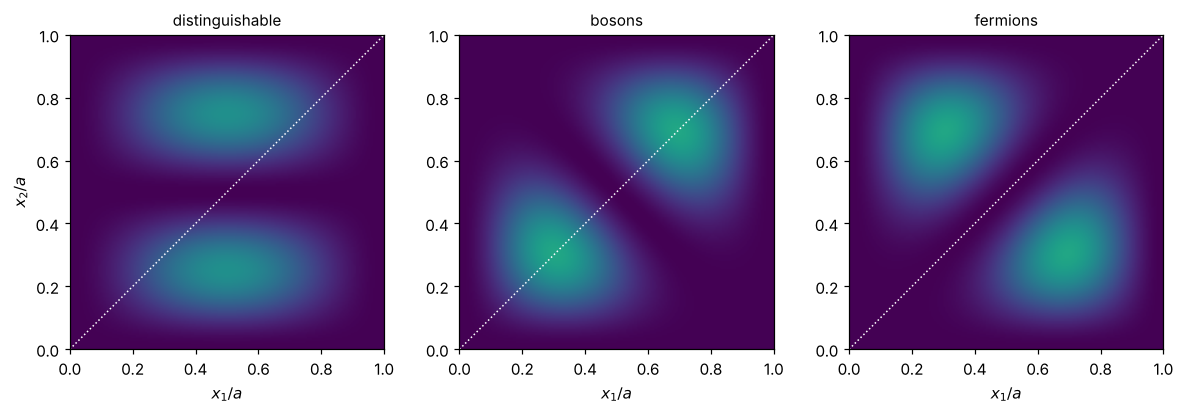

In [3]:
#| label: fig-exchange-densities
#| caption: "Joint probability density |ψ(x₁, x₂)|² for two particles in the infinite well, one in ψ₁ and one in ψ₂. Distinguishable particles (left) have no preference; symmetric bosons (middle) pile up along the diagonal x₁ = x₂; antisymmetric fermions (right) have zero probability there."
g = np.linspace(0, 1, 200); X1, X2 = np.meshgrid(g, g)
f1 = lambda x: np.sqrt(2) * np.sin(np.pi * x); f2 = lambda x: np.sqrt(2) * np.sin(2 * np.pi * x)
dens = {"distinguishable": (f1(X1) * f2(X2))**2,
        "bosons": ((f1(X1) * f2(X2) + f2(X1) * f1(X2)) / np.sqrt(2))**2,
        "fermions": ((f1(X1) * f2(X2) - f2(X1) * f1(X2)) / np.sqrt(2))**2}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, (name, D) in zip(axes, dens.items()):
    ax.imshow(D, origin="lower", extent=[0, 1, 0, 1], cmap="viridis", vmin=0, vmax=8)
    ax.plot([0, 1], [0, 1], "w:", lw=1); ax.set_title(name, fontsize=10); ax.set_xlabel("$x_1/a$"); ax.grid(False)
axes[0].set_ylabel("$x_2/a$"); plt.tight_layout(); plt.show()

## Spin Enters: Space Times Spin

For electrons the *total* state, space times spin, must be antisymmetric. Topic 6 found that two spins form a symmetric triplet ($s = 1$) and an antisymmetric singlet ($s = 0$). So:

- spin **singlet** $\Rightarrow$ **symmetric** spatial wave function (electrons closer together on average);
- spin **triplet** $\Rightarrow$ **antisymmetric** spatial wave function (electrons kept apart).

Since electrons repel, the triplet usually has lower Coulomb energy. This is the origin of Hund's first rule (maximize total spin) and of ferromagnetism: the "exchange interaction" that aligns electron spins in iron is electrostatic repulsion acting through the symmetry requirement, not a magnetic force between spins.

## Helium

Two electrons around a nucleus of charge $Z = 2$:

$$
\hat H = \left(-\frac{\hbar^2}{2m}\nabla_1^2 - \frac{Ze^2}{4\pi\epsilon_0r_1}\right) + \left(-\frac{\hbar^2}{2m}\nabla_2^2 - \frac{Ze^2}{4\pi\epsilon_0r_2}\right) + \frac{e^2}{4\pi\epsilon_0|\vec r_1 - \vec r_2|} .
$$ (eq-helium-H)

The last term (electron–electron repulsion) prevents an exact solution. Ignore it first: each electron sits in a hydrogen-like orbital with energies $-Z^2(13.6\text{ eV})/n^2$. Both in $1s$ (spatially symmetric, so spin singlet) gives $E = -8\times13.6 = -109$ eV. The measured value is $-79.0$ eV: repulsion matters.

::::{prf:example} Level 2 rung: the repulsion in first order
:label: ex-helium-first-order

Estimate the repulsion energy by averaging it over the unperturbed ground state $\psi_{100}(\vec r_1)\psi_{100}(\vec r_2)$ (this is first-order perturbation theory, topic 8).

:::{dropdown} Solution
The average of $1/|\vec r_1 - \vec r_2|$ over two $1s$ clouds of size $a/Z$ is $5Z/8a$ (the code computes it, using the fact that a spherical shell acts like a point charge outside and exerts no force inside, so $1/|\vec r_1 - \vec r_2|$ averages over angles to $1/\max(r_1, r_2)$). So

$$
\langle V_{ee}\rangle = \frac58Z\cdot\frac{e^2}{4\pi\epsilon_0a} = \frac58(2)(27.2\text{ eV}) = 34.0\text{ eV},
$$

and $E\approx-109 + 34 = -74.8$ eV, within 5% of $-79.0$ eV. The variational method (topic 9) does better by letting the electrons screen each other.
:::
::::

In [4]:
r1, r2, Z = sp.symbols("r_1 r_2 Z", positive=True)
rho = lambda r: Z**3 / sp.pi * sp.exp(-2 * Z * r)          # |psi_100|^2 with a = 1
inner = sp.integrate(rho(r2) * 4 * sp.pi * r2**2 / r1, (r2, 0, r1)) + sp.integrate(rho(r2) * 4 * sp.pi * r2**2 / r2, (r2, r1, sp.oo))
avg = sp.simplify(sp.integrate(rho(r1) * 4 * sp.pi * r1**2 * inner, (r1, 0, sp.oo)))
display(Math(r"\left\langle\frac{1}{|\vec r_1 - \vec r_2|}\right\rangle_{1s^2} = " + sp.latex(avg) + r"\ \frac1a"))
display(Math(rf"E \approx -8(13.6) + \tfrac58(2)(27.21) = {-8 * 13.606 + 5 / 8 * 2 * 27.211:.1f}\ \text{{eV}}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

**Excited states: parahelium and orthohelium.** With one electron in $1s$ and the other in $2s$ or $2p$, the spatial state can be symmetric (spin singlet, **parahelium**) or antisymmetric (spin triplet, **orthohelium**). The triplet keeps the electrons apart, so it lies lower: the $1s2s$ triplet is about 0.8 eV below the singlet. Transitions between the two families are nearly forbidden (the electric dipole interaction does not touch spin), and early spectroscopists thought helium was two different elements.

## The Periodic Table

For heavier atoms, the crude picture is: each electron moves in the average field of the nucleus and the other electrons, so the states are hydrogen-like orbitals $(n, \ell, m_\ell, m_s)$, each holding one electron by the Pauli principle. Fill them in order of energy. Screening by inner electrons raises the energy of higher-$\ell$ orbitals (a $2p$ electron spends less time near the nucleus than a $2s$, topic 5's centrifugal barrier), so for a given $n$, $s$ fills before $p$ before $d$, and $4s$ even fills before $3d$.

Closed shells (He, Ne, Ar) hold their electrons tightly; an extra electron outside a closed shell (Li, Na, K) is shielded and easy to remove. The ionization energies show the pattern.

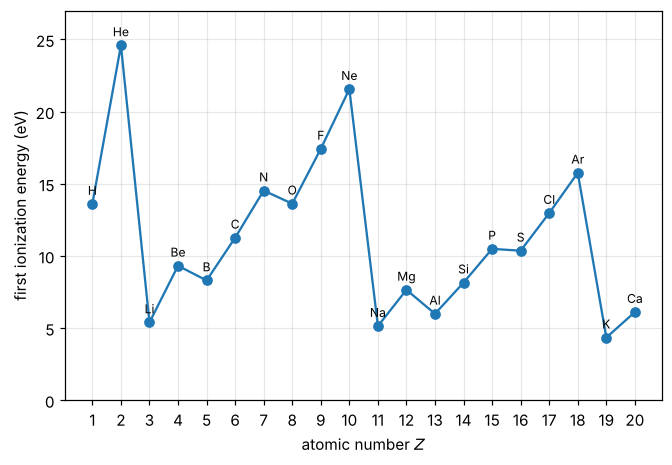

In [5]:
#| label: fig-ionization-energies
#| caption: "First ionization energies for Z = 1 to 20 (measured values). Peaks at the noble gases He, Ne, Ar (closed shells) and sharp drops at Li, Na, K (one electron outside a closed shell). The small dips after Be, Mg (a new p subshell starts) and after N, P (the first paired p electron) are the subshell structure and Hund's rule at work."
sym = "H He Li Be B C N O F Ne Na Mg Al Si P S Cl Ar K Ca".split()
IE = [13.60, 24.59, 5.39, 9.32, 8.30, 11.26, 14.53, 13.62, 17.42, 21.56, 5.14, 7.65, 5.99, 8.15, 10.49, 10.36, 12.97, 15.76, 4.34, 6.11]
Zs = np.arange(1, 21)
fig, ax = plt.subplots()
ax.plot(Zs, IE, "o-")
for zz, s_, e in zip(Zs, sym, IE): ax.annotate(s_, (zz, e), (0, 6), textcoords="offset points", ha="center", fontsize=8)
ax.set_xticks(Zs); ax.set_xlabel("atomic number $Z$"); ax.set_ylabel("first ionization energy (eV)"); ax.set_ylim(0, 27); plt.show()

## Slater Determinants

For $N$ fermions in orbitals $\phi_1, \ldots, \phi_N$, the antisymmetric combination is a determinant,

$$
\psi = \frac{1}{\sqrt{N!}}\det\begin{pmatrix}\phi_1(1) & \phi_2(1) & \cdots & \phi_N(1)\\ \phi_1(2) & \phi_2(2) & \cdots & \phi_N(2)\\ \vdots & & & \vdots\\ \phi_1(N) & \cdots & & \phi_N(N)\end{pmatrix},
$$ (eq-slater)

where $(i)$ stands for particle $i$'s position and spin. Swapping two particles swaps two rows (sign change), and two identical orbitals give two equal columns (zero): both properties of determinants (mechanics M6) are exactly the physics.

## Looking Ahead to Level 3

Writing determinants for $10^{23}$ electrons is hopeless. Sakurai's **second quantization** keeps only the occupation numbers, $|n_1, n_2, \ldots\rangle$, and uses creation and annihilation operators like the oscillator's $\hat a_\pm$ (topic 3). For bosons they obey $[\hat a_i, \hat a_j^\dagger] = \delta_{ij}$; for fermions, anticommutators $\{\hat c_i, \hat c_j^\dagger\} = \delta_{ij}$, which make $(\hat c_i^\dagger)^2 = 0$: you cannot create two fermions in the same state. The symmetry is built into the algebra.

## Exercises

### Exercises

1. Write the normalized two-particle wave function for two identical bosons both in $\psi_1$ of the infinite well, and for two identical fermions (spin ignored) in $\psi_1$ and $\psi_3$.
2. Show that $\psi_\pm$ in {eq}`eq-symmetrized` are normalized if $\psi_a$ and $\psi_b$ are orthonormal.
3. Derive {eq}`eq-exchange-separation`.
4. What is the ground-state configuration of carbon ($Z = 6$), and what total spin does Hund's first rule predict?
5. Three noninteracting electrons are in a 1D infinite well. Find the ground-state energy in units of $E_1 = \pi^2\hbar^2/2ma^2$, and compare with three spinless bosons.

:::{dropdown} Hints
1. Bosons in the same state need no symmetrizing.
2. Expand $\int|\psi_\pm|^2$; cross terms are products of overlaps.
3. Expand $(x_1 - x_2)^2$; the exchange terms involve $\int x\psi_a\psi_b$.
4. Fill 1s, 2s, 2p; the two 2p electrons go in different $m_\ell$ with parallel spins.
5. Each spatial level holds two electrons (up and down).
:::

:::{dropdown} Answers
1. $\psi_1(x_1)\psi_1(x_2)$; $\tfrac{1}{\sqrt2}[\psi_1(x_1)\psi_3(x_2) - \psi_3(x_1)\psi_1(x_2)]$.
2. $\tfrac12(1 + 1\pm2|\langle a|b\rangle|^2) = 1$ when $\langle a|b\rangle = 0$.
3. $\langle(x_1 - x_2)^2\rangle = \langle x^2\rangle_a + \langle x^2\rangle_b - 2\langle x\rangle_a\langle x\rangle_b\mp2|\langle x\rangle_{ab}|^2$.
4. $1s^22s^22p^2$; total spin $S = 1$ (a triplet), which is carbon's ground term.
5. Electrons: $2E_1 + 4E_1 = 6E_1$ (two in $n = 1$, one in $n = 2$). Bosons: $3E_1$.
:::

## Summary

- Identical particles have wave functions symmetric (bosons) or antisymmetric (fermions) under exchange; fermions obey Pauli exclusion.
- Exchange symmetry changes spatial correlations: bosons bunch, fermions avoid each other, with no force involved.
- For electrons, spin singlet goes with symmetric space and triplet with antisymmetric space; repulsion then favors the triplet (Hund's rule, ferromagnetism).
- Helium: $-109$ eV without repulsion, $-74.8$ eV with it in first order, $-79.0$ eV measured; para- and orthohelium are the singlet and triplet families.
- Shell filling plus screening explains the periodic table; Slater determinants build antisymmetric many-electron states.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.